# Лабораторная работа №1: Первичное исследование и оценка качества данных

## 1. Постановка задачи

**Что это за данные:** 
Датасет содержит информацию о 2000 клиентах сервиса. В таблице 19 признаков: демографические данные (возраст, пол, регион), финансовые показатели (годовой доход, общие траты), информация о взаимодействии с сервисом (количество звонков в поддержку, время сессий) и даты (дата регистрации, последний вход). 

**Кто заказчик:** 
Условный заказчик — отдел маркетинга и удержания клиентов (Retention Team). Их цель — понять, какие клиенты уходят (Churn_Label), и вовремя предложить им выгодные условия.

**Задачи интеллектуального анализа данных:**
1. **Сегментация клиентов:** разбить клиентов на группы по их доходам, тратам и активности, чтобы создавать персонализированные маркетинговые предложения.
2. **Поиск аномалий:** выявить клиентов с подозрительно высокими или нулевыми тратами при большой активности для проверки на мошенничество или ошибки ввода.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
%matplotlib inline

df = pd.read_csv('../data/dataset.csv')
df.head()

,Customer_ID,Churn_Label,Age,Gender,Location_Region,Marital_Status,Annual_Income,Membership_Tier,Join_Date,Last_Login_Date,Total_Spend_Lifetime,Items_In_Cart,Avg_Session_Duration_Min,Customer_Support_Calls,Preferred_Device,Payment_Method,Marketing_Opt_In,Last_Feedback_Text,Discount_Code_Used
0,CUST_00000,0,45,Female,West,Divorced,79239.91,Silver,2021-10-16,2023-11-02,944.99,6,12.1,0,Desktop,COD,True,Great service!,NaN
1,CUST_00001,1,24,Female,East,Married,67390.43,Platinum,2020-04-24,2023-01-02,45.50,5,19.1,2,Tablet,PayPal,False,Too expensive.,SAVE10
2,CUST_00002,0,52,Female,East,Married,96437.88,Platinum,2020-01-26,2023-05-22,1394.82,13,9.1,1,Mobile,PayPal,False,Worst experience ever.,SUMMER20
3,CUST_00003,0,45,Male,South,Married,31695.81,Platinum,2022-01-29,2023-03-16,82.44,0,11.9,2,Tablet,PayPal,True,Great service!,SAVE10
4,CUST_00004,0,31,Female,East,Divorced,47409.48,Gold,2020-10-08,2023-03-08,1068.49,16,6.1,2,Tablet,Credit Card,False,Too expensive.,NaN


In [3]:
# 2. Паспорт датасета
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

passport = pd.DataFrame({
    "Признак": df.columns,
    "Тип pandas": [str(t) for t in df.dtypes],
    "Уникальных значений": [df[c].nunique() for c in df.columns]
})
passport

Количество строк: 2000
Количество столбцов: 19


,Признак,Тип pandas,Уникальных значений
0,Customer_ID,str,2000
1,Churn_Label,int64,2
2,Age,int64,52
3,Gender,str,3
4,Location_Region,str,4
5,Marital_Status,str,4
6,Annual_Income,float64,2000
7,Membership_Tier,str,4
8,Join_Date,str,885
9,Last_Login_Date,str,366


In [4]:
# 3.1. Пропуски
missing = pd.DataFrame({
    "Пропущено (шт)": df.isna().sum(),
    "Доля (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Пропущено (шт)", ascending=False)
missing[missing["Пропущено (шт)"] > 0]

,Пропущено (шт),Доля (%)
Discount_Code_Used,508,25.40
Last_Feedback_Text,277,13.85
Gender,41,2.05


In [6]:
# 3.2. Дубликаты
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по Customer_ID:", df['Customer_ID'].duplicated().sum())

Полных дубликатов строк: 0
Дубликатов по Customer_ID: 0


In [6]:
# 3.3. Статистика
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
display(df[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Churn_Label,2000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
Age,2000.0,43.72,14.97,18.00,31.00,44.00,57.00,69.00
Annual_Income,2000.0,54969.30,14876.35,-449.33,44843.66,55310.21,65051.20,106212.81
Total_Spend_Lifetime,2000.0,989.46,970.36,1.09,291.10,698.84,1370.84,7917.33
Items_In_Cart,2000.0,12.03,7.10,0.00,6.00,12.00,18.00,24.00
Avg_Session_Duration_Min,2000.0,15.01,4.99,-1.90,11.78,15.00,18.30,31.90
Customer_Support_Calls,2000.0,1.05,1.05,0.00,0.00,1.00,2.00,7.00


Найдено выбросов в Annual_Income: 17


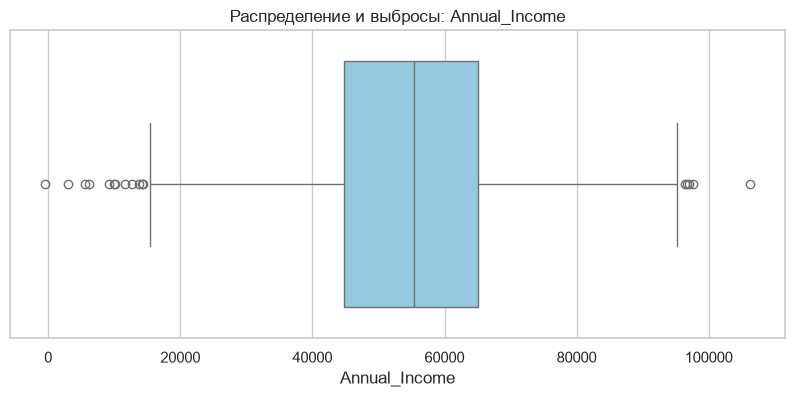

In [7]:
# 3.4. Выбросы
col = 'Annual_Income'
q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3 - q1
outliers = df[(df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)]
print(f"Найдено выбросов в {col}: {len(outliers)}")

plt.figure(figsize=(10, 4))
sns.boxplot(x=df[col], color='skyblue')
plt.title(f'Распределение и выбросы: {col}')
plt.show()

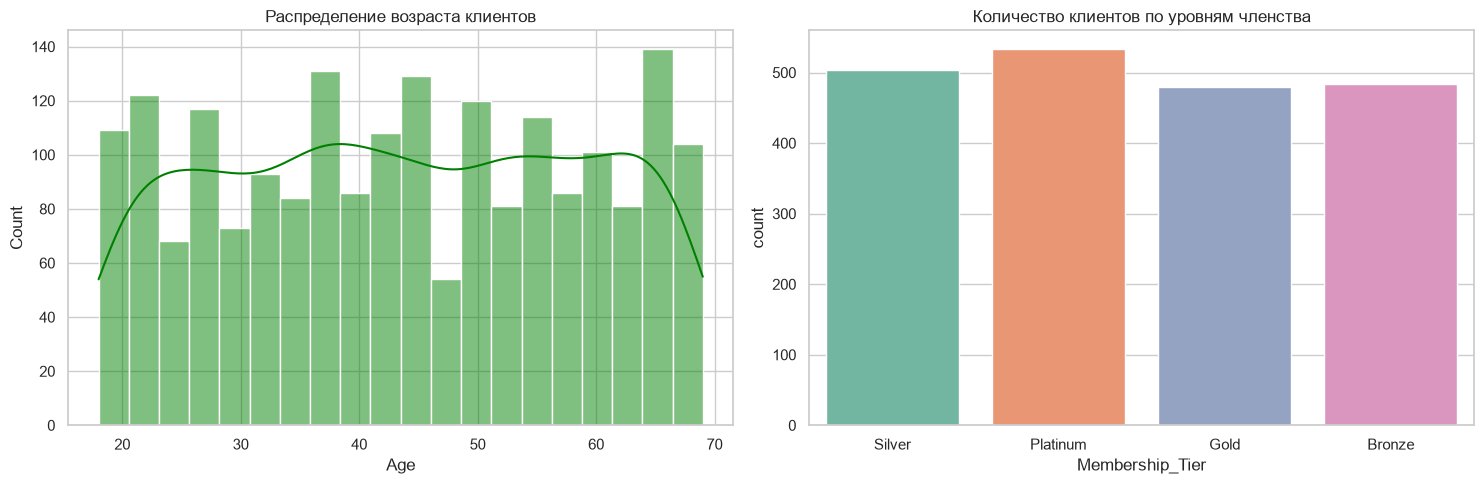

In [8]:
# 4. Графики
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Age'], bins=20, kde=True, color='green')
plt.title('Распределение возраста клиентов')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Membership_Tier', hue='Membership_Tier', palette='Set2', legend=False)
plt.title('Количество клиентов по уровням членства')

plt.tight_layout()
plt.show()

In [10]:
# 3.2. Проверка дубликатов (полный аудит)

# 1. Полные дубликаты (по всем 19 столбцам)
print("1. Полных дубликатов строк:", df.duplicated().sum())

# 2. Дубликаты только по уникальному ID клиента
print("2. Дубликатов по Customer_ID:", df['Customer_ID'].duplicated().sum())

# 3. Дубликаты по подмножеству (subset) — проверяем комбинацию Пол+Возраст+Доход
subset_dups = df.duplicated(subset=['Gender', 'Age', 'Annual_Income']).sum()
print(f"3. Дубликатов по комбинации (Gender, Age, Annual_Income): {subset_dups}")

# 4. Полные дубликаты без учета ID (по 18 столбцам)
df_no_id = df.drop(columns=['Customer_ID'])
print("4. Дубликатов без учета Customer_ID:", df_no_id.duplicated().sum())

1. Полных дубликатов строк: 0
2. Дубликатов по Customer_ID: 0
3. Дубликатов по комбинации (Gender, Age, Annual_Income): 0
4. Дубликатов без учета Customer_ID: 0
